# 01 · Exploring the strawberry cold-chain data

**Block** is an app that helps truck drivers carrying fresh produce choose the route that delivers the load with the **most shelf life left**. To score a route, we need to know how warm the cargo gets during a trip. This notebook explores a real dataset of six refrigerated strawberry shipments, cleans it, and saves a tidy table that the modeling notebooks (02 and 03) build on.

**Reads:** `model/data/strawberry_cold_chain/`, the public strawberry cold-chain dataset (arXiv 2103.12895): 6 US truck shipments with temperature loggers at up to 9 positions inside each trailer.

**Produces:** `model/data/processed/strawberry_clean.csv`, with one row per temperature reading: shipment, trailer position, time, temperature (°F and °C), a phase label (`precool` or `transit`), and two quality flags.

**Words used below:**
- *Pallet*: one of three stacks of boxes in the trailer: Front, Middle, Rear.
- *Layer*: height within a pallet: Top, Middle, Bottom.
- *Sensor*: one temperature logger, named by pallet and layer (for example `Front_Top`).

## Step 1: list every file in the dataset

**What:** Walks through the dataset folder and prints every file with its size.

**Why:** Before reading any data, we check exactly what we have: how many files, which kinds, and how they are organized. This catches surprises (missing or junk files) early.

**Result:** 58 CSV files plus 2 macOS `.DS_Store` files (system junk to ignore). `Preprocessed Data/` has one file per shipment (6). `Raw Data/` has one file per sensor (52), named like `S1_Front_Top.csv` (shipment 1, front pallet, top layer). A full 3 × 3 grid for 6 shipments would be 54 sensors; Shipment 1 is missing `Front_Bottom` and `Middle_Bottom`.

In [24]:
from pathlib import Path
import pandas as pd

data_dir = Path("../data/strawberry_cold_chain")

# Step 1: list every file, whatever its type
for path in sorted(data_dir.rglob("*")):
    if path.is_file():
        size_kb = path.stat().st_size / 1024
        print(f"{size_kb:8.1f} KB  {path.relative_to(data_dir)}")

     8.0 KB  .DS_Store
     9.2 KB  Preprocessed Data/Shipment 1.csv
     3.4 KB  Preprocessed Data/Shipment 2.csv
    28.7 KB  Preprocessed Data/Shipment 3.csv
    18.1 KB  Preprocessed Data/Shipment 4.csv
    24.9 KB  Preprocessed Data/Shipment 5.csv
    13.7 KB  Preprocessed Data/Shipment 6.csv
    10.0 KB  Raw Data/.DS_Store
    73.3 KB  Raw Data/S1_Front_Middle.csv
    35.3 KB  Raw Data/S1_Front_Top.csv
    35.2 KB  Raw Data/S1_Middle_Middle.csv
    99.5 KB  Raw Data/S1_Middle_Top.csv
    30.2 KB  Raw Data/S1_Rear_Bottom.csv
    33.3 KB  Raw Data/S1_Rear_Middle.csv
    81.7 KB  Raw Data/S1_Rear_Top.csv
    58.8 KB  Raw Data/S2_Front_Bottom.csv
    65.7 KB  Raw Data/S2_Front_Middle.csv
     2.5 KB  Raw Data/S2_Front_Top.csv
     6.1 KB  Raw Data/S2_Middle_Bottom.csv
     2.5 KB  Raw Data/S2_Middle_Middle.csv
    35.1 KB  Raw Data/S2_Middle_Top.csv
    29.0 KB  Raw Data/S2_Rear_Bottom.csv
    21.5 KB  Raw Data/S2_Rear_Middle.csv
    26.4 KB  Raw Data/S2_Rear_Top.csv
    40.5 KB  Raw

## Step 2: read the raw text of two files

**What:** Prints the first 8 lines of one raw sensor file and one preprocessed file exactly as stored, with hidden characters made visible.

**Why:** pandas (the table library) guesses a file's format when it loads it, and a wrong guess can silently mangle data. Reading the plain text first shows the real column names, date format, units and any hidden characters.

**Result:**
- The raw file has a real timestamp column, `Time` (for example `3/12/2019 12:30`: month/day/year, 24-hour clock, no time zone), and one temperature column, `T1`.
- The preprocessed file has **no real time**, only a step counter `t`, plus one column per sensor.
- **Neither file has GPS (latitude/longitude) columns.**
- Temperatures are in **°F**: 33–37°F (about 1–3°C) fits refrigerated strawberries, and 74°F at the start is room temperature.
- The raw file begins with an invisible *byte order mark* (`\ufeff`), a marker some programs such as Excel add to the start of a file. It has to be stripped when loading.
- **Decision:** use the raw files, because only they have timestamps.

In [25]:
# Step 2: look at the raw text of one raw file and one preprocessed file
files_to_peek = [
    data_dir / "Raw Data" / "S1_Front_Top.csv",
    data_dir / "Preprocessed Data" / "Shipment 1.csv",
]

for path in files_to_peek:
    print(f"===== {path.relative_to(data_dir)} =====")
    with open(path, encoding="utf-8", errors="replace") as f:
        for _ in range(8):
            line = f.readline()
            if not line:  # file has fewer than 8 lines
                break
            print(repr(line))  # repr shows hidden characters like \t, \r, \n
    print()

===== Raw Data/S1_Front_Top.csv =====
'\ufeffTime,T1\n'
'3/12/2019 12:30,73.9\n'
'3/12/2019 12:35,73.9\n'
'3/12/2019 12:42,74.1\n'
'3/12/2019 12:48,73.8\n'
'3/12/2019 12:53,73.8\n'
'3/12/2019 12:58,73.8\n'
'3/12/2019 13:03,73.8\n'

===== Preprocessed Data/Shipment 1.csv =====
't,Front_Top,Front_Middle,Middle_Top,Middle_Middle,Rear_Top,Rear_Middle,Rear_Bottom\n'
'1,33.6,34.5,31.6,34.3,32.5,34.2,34.3\n'
'2,34.3,35.2,32.7,35.2,33.3,34.5,35.1\n'
'3,34.7,35.6,33.4,35.8,33.8,34.9,35.6\n'
'4,35.1,36,34,36.1,34.3,35.1,35.8\n'
'5,35.2,36.1,34.5,36.7,34.7,35.2,36\n'
'6,35.6,36.5,34.9,36.9,34.9,35.4,36\n'
'7,35.6,36.7,35.1,37,35.2,35.6,36.1\n'



## Step 3: load every raw sensor file into one table

*This loader was written after the format survey in the next cell (Step 3b), which showed that the raw files come in several layouts. The survey is kept below it as a record of what we found.*

**What:** Reads all 52 raw files. For each file it finds the header line, takes the temperature column right after `Time`, cleans values like `74.7F`, converts °F to °C, and stacks everything into one long table `df` (one row per reading). It then prints a check table with one row per file.

**Why:**
- The files don't share one layout, so the loader **searches for the header line** instead of assuming it is line 1, and picks the temperature column **by position** instead of by name.
- Unreadable values become blanks and are **counted** instead of crashing the loop, so any problem is visible.
- A long table (one row per reading, with shipment/pallet/layer columns) makes grouping and plotting easy.
- We convert to °C because the rest of the project uses metric units.

**Result:**
- All 52 files load, with **0 bad temperatures and 0 bad times**: 68,332 readings in total.
- Every sensor starts at room temperature (23–28°C), and many keep recording for **1–3 weeks after the trip**, reaching 40–46°C. The data must be trimmed to the actual trip (Step 5).
- `S2_Middle_Top` dips to **−6.5°C**, far below every other sensor (examined in Step 4b).

In [26]:
# Step 3: load every raw sensor file into one long table (one row per reading)
import io


def read_sensor_file(path):
    """Read one raw sensor CSV (any of the surveyed formats) into columns time, temp_f."""
    raw_bytes = path.read_bytes()
    try:
        text = raw_bytes.decode("utf-8-sig")
    except UnicodeDecodeError:
        text = raw_bytes.decode("latin-1")  # S1_Rear_Top starts with a few junk bytes

    # The header is the first line mentioning "Time"; everything above it is metadata or junk
    lines = text.splitlines()
    header_index = next((i for i, line in enumerate(lines) if "Time" in line), None)
    if header_index is None:
        raise ValueError("no header line containing 'Time'")

    # dtype=str keeps values as text, so "74.7F" and "73.9" are cleaned the same way
    raw = pd.read_csv(io.StringIO("\n".join(lines[header_index:])), dtype=str)

    # The temperature is whatever column comes right after "Time" (T1, "Ship 2 - MB", unnamed...)
    columns = list(raw.columns)
    temp_column = columns[columns.index("Time") + 1]

    sensor_df = pd.DataFrame()
    sensor_df["time"] = pd.to_datetime(raw["Time"], format="%m/%d/%Y %H:%M", errors="coerce")
    sensor_df["temp_f"] = pd.to_numeric(raw[temp_column].str.strip().str.rstrip("F"), errors="coerce")
    return sensor_df


frames = []
file_stats = []
csv_paths = sorted((data_dir / "Raw Data").glob("*.csv"))

for path in csv_paths:
    try:
        # "S1_Front_Top" -> ["S1", "Front", "Top"]
        shipment_part, pallet, layer = path.stem.split("_")
        shipment = int(shipment_part[1:])
        sensor_df = read_sensor_file(path)
    except Exception as e:
        print(f"FAILED: {path.name}: {e}")
        continue

    sensor_df["temp_c"] = (sensor_df["temp_f"] - 32) * 5 / 9
    sensor_df["shipment"] = shipment
    sensor_df["pallet"] = pallet
    sensor_df["layer"] = layer
    frames.append(sensor_df[["shipment", "pallet", "layer", "time", "temp_f", "temp_c"]])

    file_stats.append({
        "file": path.name,
        "rows": len(sensor_df),
        "bad_temps": sensor_df["temp_f"].isna().sum(),
        "bad_times": sensor_df["time"].isna().sum(),
        "first_time": sensor_df["time"].min(),
        "last_time": sensor_df["time"].max(),
        "min_c": sensor_df["temp_c"].min(),
        "max_c": sensor_df["temp_c"].max(),
    })

df = pd.concat(frames, ignore_index=True)

print(f"Files loaded: {len(frames)} of {len(csv_paths)}\n")
print(pd.DataFrame(file_stats).round(1).to_string(index=False))
print(f"\nTotal rows: {len(df)}")
print(df.head())

Files loaded: 52 of 52

                file  rows  bad_temps  bad_times          first_time           last_time  min_c  max_c
 S1_Front_Middle.csv  2663          0          0 2019-03-12 12:28:00 2019-03-22 10:19:00   -0.2   33.9
    S1_Front_Top.csv  1699          0          0 2019-03-12 12:30:00 2019-03-18 21:58:00   -0.4   36.6
S1_Middle_Middle.csv  1300          0          0 2019-03-12 12:26:00 2019-03-22 09:27:00    0.5   34.0
   S1_Middle_Top.csv  3599          0          0 2019-03-12 12:30:00 2019-03-25 23:50:00   -0.6   34.1
  S1_Rear_Bottom.csv  1118          0          0 2019-03-12 12:29:00 2019-03-21 08:04:00    1.1   33.5
  S1_Rear_Middle.csv  1230          0          0 2019-03-12 12:29:00 2019-03-22 02:01:00    0.5   33.7
     S1_Rear_Top.csv  2964          0          0 2019-03-12 12:26:00 2019-04-03 08:42:00    0.2   40.0
 S2_Front_Bottom.csv  2171          0          0 2019-04-04 03:07:00 2019-04-20 18:08:00    0.1   27.0
 S2_Front_Middle.csv  2414          0          0 

## Step 3b: survey the format of every raw file

**What:** Reads the first three lines of every raw file as plain text and groups files that share the same layout.

**Why:** The first version of the loader assumed every file looked like `S1_Front_Top.csv`, and it failed on 49 of the 52 files. This survey shows every layout, so the loader (Step 3 above) could be written to handle all of them.

**Result:** Every file uses commas and the same date format, but there are four layouts:
- **46 files:** a `Sensor,<id>` line first, then the header `#,Time,T1`, with temperatures written like `74.7F`. 41 of them have an extra empty column at the end; 5 don't.
- **3 files:** a clean `Time,T1` header with plain numbers. These were already trimmed by the dataset's authors, which becomes useful in Step 5.
- **2 one-offs:** in `S3_Rear_Middle` the temperature column has no name; in `S2_Middle_Bottom` it is named `Ship 2 - MB`.
- **`S1_Rear_Top`:** starts with a few junk bytes.

**Note on the output:** the survey lists `S1_Rear_Top` as "utf-16" and prints garbled characters. That label is **wrong**. An *encoding* is the rule for turning a file's bytes into letters; decoding this file as UTF-16 "worked" but produced nonsense. The file is ordinary text with 3 junk bytes at the start, and the Step 3 loader reads it correctly using its `latin-1` fallback.

In [27]:
# Step 3b: format survey - what do the first lines of every raw file look like?
rows = []

for path in sorted((data_dir / "Raw Data").glob("*.csv")):
    raw_bytes = path.read_bytes()
    for encoding in ["utf-8-sig", "utf-16", "latin-1"]:
        try:
            # decode the whole file, so a bad byte anywhere (not just line 1) counts as a failure
            text = raw_bytes.decode(encoding)
            break
        except UnicodeDecodeError:
            continue  # latin-1 never fails, so text is always set
    lines = text.splitlines(keepends=True)[:3]
    lines += [""] * (3 - len(lines))  # pad very short files
    rows.append({
        "file": path.name,
        "encoding": encoding,
        "line1": repr(lines[0]),
        "line2": repr(lines[1]),
        "line3": repr(lines[2]),
    })

survey = pd.DataFrame(rows)

# Every file has its own sensor ID in line 1, so hide it to group files by layout
survey["header"] = survey["line1"].str.replace(r"Sensor,[^,]*", "Sensor,<id>", regex=True)

print(survey["encoding"].value_counts().to_string())
print()
for header, group in survey.groupby("header"):
    first = group.iloc[0]
    print(f"{len(group):2d} files  line1 = {header}")
    print(f"          e.g. line2 = {first['line2']}  line3 = {first['line3']}")
    print("          " + ", ".join(group["file"]))
    print()

print("Files that needed a non-UTF-8 encoding:")
for _, row in survey[survey["encoding"] != "utf-8-sig"].iterrows():
    print(f"{row['file']} ({row['encoding']})")
    print("  line1:", row["line1"])
    print("  line2:", row["line2"])
    print("  line3:", row["line3"])

encoding
utf-8-sig    51
utf-16        1

 1 files  line1 = '#,Time,Ship 2 - MB\r\n'
          e.g. line2 = '1,4/4/2019 3:04,79.3\r\n'  line3 = '2,4/4/2019 3:21,79.5\r\n'
          S2_Middle_Bottom.csv

41 files  line1 = 'Sensor,<id>,,\r\n'
          e.g. line2 = '#,Time,T1,\r\n'  line3 = '1,3/12/2019 12:28,74.7F,\r\n'
          S1_Front_Middle.csv, S1_Middle_Middle.csv, S1_Middle_Top.csv, S1_Rear_Bottom.csv, S1_Rear_Middle.csv, S2_Front_Bottom.csv, S2_Front_Middle.csv, S2_Front_Top.csv, S2_Middle_Middle.csv, S2_Middle_Top.csv, S2_Rear_Bottom.csv, S2_Rear_Middle.csv, S2_Rear_Top.csv, S3_Front_Bottom.csv, S3_Front_Middle.csv, S3_Front_Top.csv, S3_Middle_Bottom.csv, S3_Middle_Middle.csv, S3_Middle_Top.csv, S3_Rear_Bottom.csv, S3_Rear_Top.csv, S4_Front_Bottom.csv, S4_Front_Middle.csv, S4_Front_Top.csv, S4_Middle_Bottom.csv, S4_Middle_Middle.csv, S4_Middle_Top.csv, S4_Rear_Bottom.csv, S4_Rear_Middle.csv, S5_Front_Bottom.csv, S5_Front_Top.csv, S5_Middle_Bottom.csv, S5_Middle_Middle.csv, S5_

## Step 4: plot one shipment

**What:** Plots temperature over time for every sensor in Shipment 3, with dashed reference lines at 0°C and 4°C.

**Why:** A chart shows the shape of a trip at a glance: when the fruit is cooled, how steady the cold is, and where the data stops being a trip. The two dashed lines mark the cold band the trucks hold most of the time. They were chosen as visual references, not from a standard (strawberries keep best near 0°C).

**Result:** Four phases are visible:
1. A short warm start (16–21°C on 7/9).
2. A fast cool-down to about 0°C within hours.
3. Steady cold transport at about 1–4.5°C until about 7/15.
4. Sensors warming **one by one** between 7/15 and 7/19, most likely as pallets were unloaded at different times.

The warming tail is not part of the trip and has to be cut.

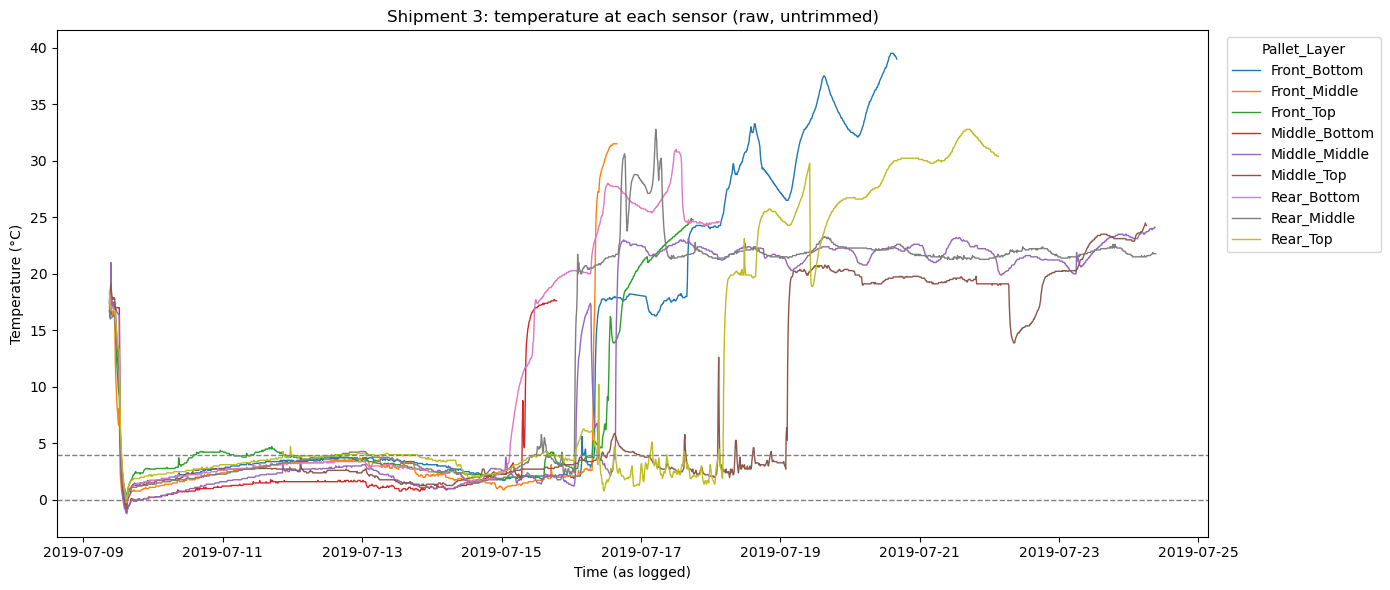

In [28]:
# Step 4: plot every sensor of Shipment 3 on one chart
import matplotlib.pyplot as plt

ship3 = df[df["shipment"] == 3]

fig, ax = plt.subplots(figsize=(14, 6))
for (pallet, layer), sensor_df in ship3.groupby(["pallet", "layer"]):
    sensor_df = sensor_df.sort_values("time")  # lines must be drawn in time order
    ax.plot(sensor_df["time"], sensor_df["temp_c"], label=f"{pallet}_{layer}", linewidth=1)

ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.axhline(4, color="gray", linestyle="--", linewidth=1)
ax.set_title("Shipment 3: temperature at each sensor (raw, untrimmed)")
ax.set_xlabel("Time (as logged)")
ax.set_ylabel("Temperature (°C)")
ax.legend(title="Pallet_Layer", bbox_to_anchor=(1.01, 1), loc="upper left")  # legend outside the plot
plt.tight_layout()
plt.show()

## Step 4b: zoom in on the −6.5°C reading

**What:** Finds `S2_Middle_Top`'s coldest reading, plots 12 hours either side of it, and prints every reading within 1 hour.

**Why:** −6.5°C is far below every other sensor, which all stay above −1.2°C. We need to know whether it is a one-off glitch (a single bad reading, safe to delete) or something that really happened to the fruit.

**Result:** It is a **sustained event, not a glitch**: about 3 hours below 0°C, with a smooth fall and rise, right after a short warm spike to 12°C around 15:00. One possible explanation is that the sensor was taken out (door open or inspection) and put back near the cold-air outlet, but the data can't confirm this. **Decision:** keep these readings and flag them as a `handling_event` (Step 7).

Minimum -6.5 °C at 2019-04-05 17:53:00



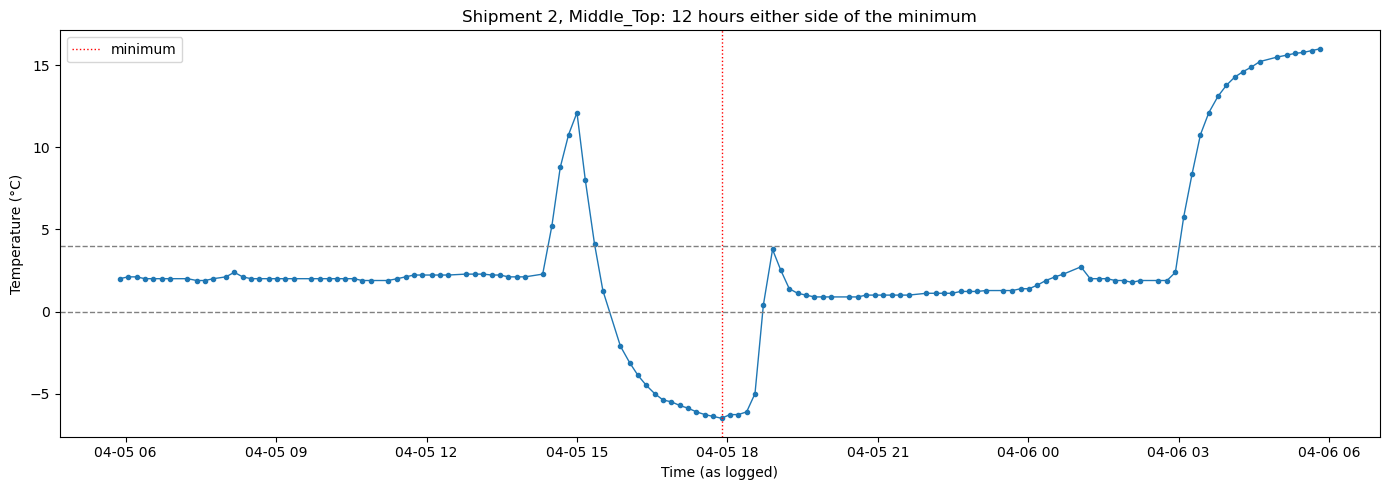

               time  temp_f  temp_c
2019-04-05 16:53:00    22.1    -5.5
2019-04-05 17:03:00    21.7    -5.7
2019-04-05 17:13:00    21.4    -5.9
2019-04-05 17:23:00    21.0    -6.1
2019-04-05 17:33:00    20.7    -6.3
2019-04-05 17:43:00    20.5    -6.4
2019-04-05 17:53:00    20.3    -6.5
2019-04-05 18:03:00    20.7    -6.3
2019-04-05 18:13:00    20.7    -6.3
2019-04-05 18:23:00    21.0    -6.1
2019-04-05 18:33:00    23.0    -5.0
2019-04-05 18:43:00    32.7     0.4


In [29]:
# Step 4b: zoom in on S2_Middle_Top around its -6.5°C minimum
s2_middle_top = df[
    (df["shipment"] == 2) & (df["pallet"] == "Middle") & (df["layer"] == "Top")
].sort_values("time")

min_time = s2_middle_top.loc[s2_middle_top["temp_c"].idxmin(), "time"]
print(f"Minimum {s2_middle_top['temp_c'].min():.1f} °C at {min_time}\n")

# 12 hours on each side for the plot
window = s2_middle_top[
    (s2_middle_top["time"] >= min_time - pd.Timedelta(hours=12))
    & (s2_middle_top["time"] <= min_time + pd.Timedelta(hours=12))
]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(window["time"], window["temp_c"], marker=".", linewidth=1)  # dots show each reading
ax.axvline(min_time, color="red", linestyle=":", linewidth=1, label="minimum")
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.axhline(4, color="gray", linestyle="--", linewidth=1)
ax.set_title("Shipment 2, Middle_Top: 12 hours either side of the minimum")
ax.set_xlabel("Time (as logged)")
ax.set_ylabel("Temperature (°C)")
ax.legend()
plt.tight_layout()
plt.show()

# 1 hour on each side as a table: one odd reading, or a sustained drop?
close_by = s2_middle_top[(s2_middle_top["time"] - min_time).abs() <= pd.Timedelta(hours=1)]
print(close_by[["time", "temp_f", "temp_c"]].round(1).to_string(index=False))

## Step 5: trim each shipment to its official trip window

**What:** Uses each shipment's total trip duration from Table 2 of the dataset paper (harvest + precooling + transport) to define a window: start = the shipment's earliest reading, end = start + duration. It checks this rule against the three files the authors had already trimmed, then keeps only readings inside the window (`df_trip`).

**Why:** The sensors kept recording long after delivery, so we need a trusted trip boundary, and the paper's durations are the best available source. Checking the rule against the authors' own trimmed files tests it before we rely on it. The cell stops with an error if the check fails.

**Result:**
- The durations match the authors' trimmed files **to the minute**. Our start times are 4–16 minutes earlier than theirs, which we accepted (the check allows 20 minutes).
- **36,790 of 68,332 readings kept (54%).** All 52 sensors keep some data.
- **Short sensors:** `S6_Front_Bottom` keeps only 54 readings (about 10 hours). `S2_Front_Top` and `S2_Middle_Middle` cover only about 19 of Shipment 2's 49 hours.
- The trimmed Shipment 3 chart still shows two sensors (Rear_Bottom, Middle_Bottom) warming in the last ~18 hours. Their pallets seem to have left the cold before the official end.

                window_start          window_end
shipment                                        
1        2019-03-12 12:26:00 2019-03-18 21:54:00
2        2019-04-04 03:03:00 2019-04-06 04:12:00
3        2019-07-09 08:56:00 2019-07-15 18:21:00
4        2019-07-09 08:56:00 2019-07-14 21:01:00
5        2019-07-10 10:19:00 2019-07-17 01:12:00
6        2019-07-10 10:18:00 2019-07-14 14:53:00

           file          file_first        window_start  start_diff_min           file_last          window_end  end_diff_min
   S1_Front_Top 2019-03-12 12:30:00 2019-03-12 12:26:00             4.0 2019-03-18 21:58:00 2019-03-18 21:54:00           4.0
    S4_Rear_Top 2019-07-09 09:12:00 2019-07-09 08:56:00            16.0 2019-07-14 21:17:00 2019-07-14 21:01:00          16.0
S5_Front_Middle 2019-07-10 10:24:00 2019-07-10 10:19:00             5.0 2019-07-17 01:17:00 2019-07-17 01:12:00           5.0

                        rows_before  rows_after  any_left        flag
shipment pallet layer           

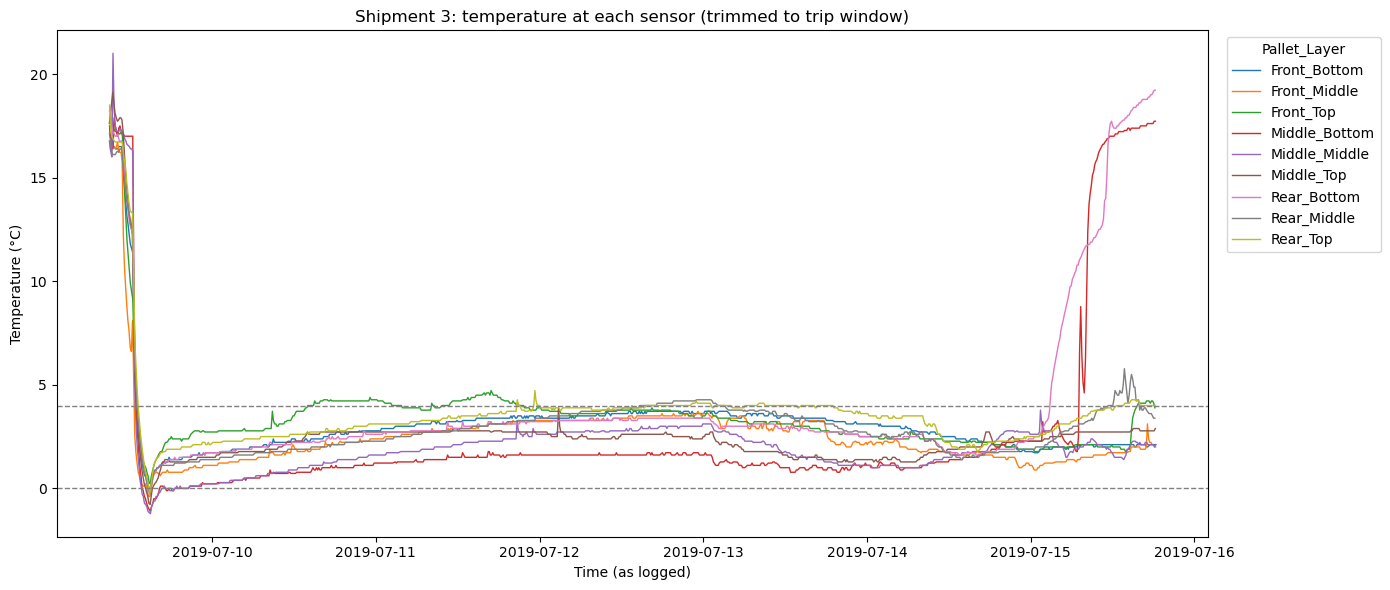

In [30]:
# Step 5: trim every sensor to its shipment's official trip window

# Total duration (harvest + precooling + transport) per shipment, from Table 2 of the
# dataset paper (arXiv 2103.12895)
durations = {
    1: pd.Timedelta(days=6, hours=9, minutes=28),
    2: pd.Timedelta(days=2, hours=1, minutes=9),
    3: pd.Timedelta(days=6, hours=9, minutes=25),
    4: pd.Timedelta(days=5, hours=12, minutes=5),
    5: pd.Timedelta(days=6, hours=14, minutes=53),
    6: pd.Timedelta(days=4, hours=4, minutes=35),
}

# Window = earliest reading of any sensor in the shipment, plus the paper's duration
windows = pd.DataFrame({"window_start": df.groupby("shipment")["time"].min()})
windows["window_end"] = windows["window_start"] + pd.Series(durations)
print(windows.to_string())

# Check the rule against the 3 files the authors already trimmed ("Time,T1" format).
# Their windows start 4-16 min after our earliest-sensor start, so allow 20 min.
tolerance = pd.Timedelta(minutes=20)
checks = []
for shipment, pallet, layer in [(1, "Front", "Top"), (4, "Rear", "Top"), (5, "Front", "Middle")]:
    times = df[(df["shipment"] == shipment) & (df["pallet"] == pallet) & (df["layer"] == layer)]["time"]
    window_start, window_end = windows.loc[shipment]
    checks.append({
        "file": f"S{shipment}_{pallet}_{layer}",
        "file_first": times.min(),
        "window_start": window_start,
        "start_diff_min": (times.min() - window_start).total_seconds() / 60,
        "file_last": times.max(),
        "window_end": window_end,
        "end_diff_min": (times.max() - window_end).total_seconds() / 60,
    })
checks = pd.DataFrame(checks)
print()
print(checks.to_string(index=False))
max_diff = checks[["start_diff_min", "end_diff_min"]].abs().max().max()
assert max_diff <= tolerance.total_seconds() / 60, f"window rule off by {max_diff:.0f} min - stop and check"

# Keep only rows inside their shipment's window (df itself is not changed)
row_start = df["shipment"].map(windows["window_start"])
row_end = df["shipment"].map(windows["window_end"])
df_trip = df[df["time"].between(row_start, row_end)]

# Rows per sensor before and after trimming
sensor_columns = ["shipment", "pallet", "layer"]
counts = pd.DataFrame({
    "rows_before": df.groupby(sensor_columns).size(),
    "rows_after": df_trip.groupby(sensor_columns).size(),
}).fillna(0).astype(int)  # a sensor with no rows left is missing from df_trip -> 0
counts["any_left"] = counts["rows_after"] > 0
counts["flag"] = counts["rows_after"].lt(100).map({True: "< 100 rows", False: ""})
print()
print(counts.to_string())
print(f"\nRows kept: {len(df_trip)} of {len(df)} ({len(df_trip) / len(df):.0%})")

# Shipment 3 again, now trimmed (same style as Step 4)
ship3_trip = df_trip[df_trip["shipment"] == 3]

fig, ax = plt.subplots(figsize=(14, 6))
for (pallet, layer), sensor_df in ship3_trip.groupby(["pallet", "layer"]):
    sensor_df = sensor_df.sort_values("time")
    ax.plot(sensor_df["time"], sensor_df["temp_c"], label=f"{pallet}_{layer}", linewidth=1)

ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.axhline(4, color="gray", linestyle="--", linewidth=1)
ax.set_title("Shipment 3: temperature at each sensor (trimmed to trip window)")
ax.set_xlabel("Time (as logged)")
ax.set_ylabel("Temperature (°C)")
ax.legend(title="Pallet_Layer", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Step 6a: plot all six shipments

**What:** Draws one subplot per shipment, each trimmed to its trip window. Every trailer position has the same color in every subplot, so one legend covers them all.

**Why:** Until now only Shipment 3 had been plotted. We need to see whether pallets leaving the cold early happens in the other shipments too.

**Result:** It does. For example, Shipment 4's middle pallet warms to about 20°C more than a day before its window ends. Shipment 1 also has an unusually long warm start: about 43 hours at 23–35°C before cooling.

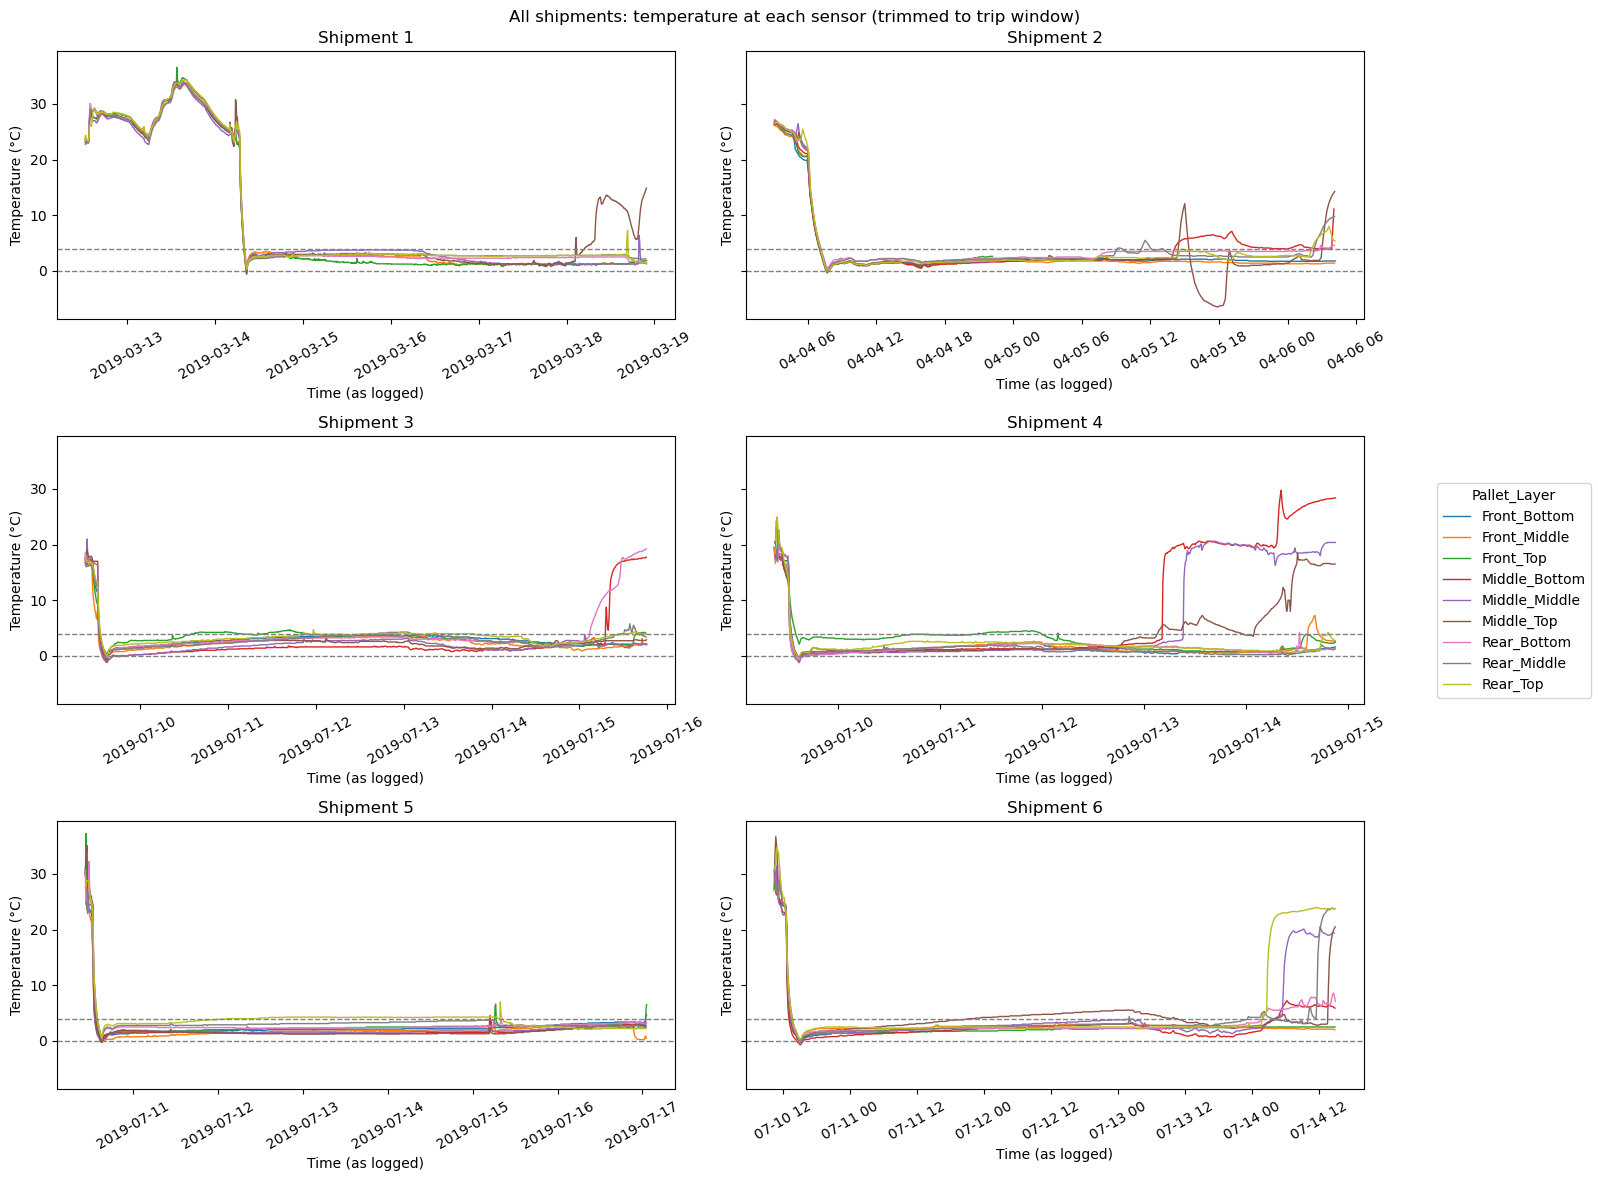

In [31]:
# Step 6a: all six shipments, trimmed to their trip windows, one subplot each

# Give each trailer position the same color in every subplot, so one legend fits all
positions = sorted((df_trip["pallet"] + "_" + df_trip["layer"]).unique())
position_colors = dict(zip(positions, plt.cm.tab10.colors))

fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharey=True)
lines_for_legend = {}

for ax, (shipment, ship_df) in zip(axes.flat, df_trip.groupby("shipment")):
    for (pallet, layer), sensor_df in ship_df.groupby(["pallet", "layer"]):
        sensor_df = sensor_df.sort_values("time")
        position = f"{pallet}_{layer}"
        (line,) = ax.plot(sensor_df["time"], sensor_df["temp_c"], color=position_colors[position], linewidth=1)
        lines_for_legend[position] = line

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.axhline(4, color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"Shipment {shipment}")
    ax.set_xlabel("Time (as logged)")
    ax.set_ylabel("Temperature (°C)")
    ax.tick_params(axis="x", labelrotation=30)

fig.legend(
    [lines_for_legend[p] for p in positions], positions,
    title="Pallet_Layer", loc="center right",
)
fig.suptitle("All shipments: temperature at each sensor (trimmed to trip window)")
plt.tight_layout(rect=(0, 0, 0.88, 1))  # leave room on the right for the legend
plt.show()

## Step 6b: find when each sensor "left the cold"

**What:** For each sensor, finds two times:
- `cooled_at`: the first reading at or below 4°C, meaning the cool-down is finished.
- `left_cold_at`: the first time it went above 8°C and either stayed there for 2 hours, or stayed there until its data ended.

**Why:**
- The paper gives one end time per shipment, but pallets were clearly unloaded at different times, so the cut has to be found **per sensor**.
- The 2 hours are measured in **clock time, not number of readings**, because sensors log at different rates (roughly every 5 or every 10 minutes).
- The "until its data ended" part catches pallets unloaded in the **last hour** of a window, which a 2-hour test alone would miss.
- The thresholds (4°C, 8°C, 2 hours) are judgment calls made for this project by looking at the charts, not values from a published source. The 2-hour minimum makes sure short handling spikes aren't mistaken for unloading: S2_Middle_Top's spike, for example, lasted about 30 minutes.

**Result:**
- **13 sensors left the cold before their window ended:** Shipment 1: 1, Shipment 2: 3, Shipment 3: 2, Shipment 4: 3, Shipment 5: 0, Shipment 6: 4.
- The times match where the charts show a line jumping up.
- `S2_Middle_Top`'s 30-minute warm spike was correctly **not** counted as leaving the cold.

*The "until its data ended" part of the rule was added after this cell first ran. The saved output reflects the updated rule.*

In [32]:
# Step 6b: for each sensor, find a candidate time when its pallet "left the cold"
COLD_C = 4  # at or below this, cool-down is finished
WARM_C = 8  # above this for a while = out of refrigeration
MIN_WARM = pd.Timedelta(hours=2)  # elapsed time, not rows: sensors log at different rates


def find_left_cold(sensor_df):
    """Return (cooled_at, left_cold_at) for one sensor; either can be None.

    Left the cold = above WARM_C for MIN_WARM, or above WARM_C until the data ends.
    """
    sensor_df = sensor_df.sort_values("time")

    cold_rows = sensor_df[sensor_df["temp_c"] <= COLD_C]
    if cold_rows.empty:
        return None, None  # never cooled down
    cooled_at = cold_rows["time"].iloc[0]

    # Walk forward from cooled_at, tracking when the current run above WARM_C started
    warm_since = None
    for time, temp in zip(sensor_df["time"], sensor_df["temp_c"]):
        if time < cooled_at:
            continue
        if temp > WARM_C:
            if warm_since is None:
                warm_since = time
            if time - warm_since >= MIN_WARM:
                return cooled_at, warm_since  # warm for 2+ hours: left the cold when the run began
        else:
            warm_since = None  # dropped back below, so the run is broken
    # Still warm when the data ends (any length): left the cold, e.g. unloaded in the last hour
    return cooled_at, warm_since


rows = []
for (shipment, pallet, layer), sensor_df in df_trip.groupby(["shipment", "pallet", "layer"]):
    cooled_at, left_cold_at = find_left_cold(sensor_df)
    window_end = windows.loc[shipment, "window_end"]
    # last reading, not window_end: a short sensor (S6_Front_Bottom) stops long before the window ends
    cold_until = left_cold_at if left_cold_at is not None else sensor_df["time"].max()
    rows.append({
        "shipment": shipment,
        "pallet_layer": f"{pallet}_{layer}",
        "cooled_at": cooled_at,
        "left_cold_at": left_cold_at if left_cold_at is not None else "stayed cold",
        "hours_cold": (cold_until - cooled_at) / pd.Timedelta(hours=1) if cooled_at is not None else None,
        "hours_before_end": (window_end - left_cold_at) / pd.Timedelta(hours=1) if left_cold_at is not None else None,
    })

left_cold = pd.DataFrame(rows)
print(left_cold.round(1).to_string(index=False))

print("\nSensors that left the cold before the window end, per shipment:")
print(left_cold.groupby("shipment")["hours_before_end"].count().to_string())

 shipment  pallet_layer           cooled_at        left_cold_at  hours_cold  hours_before_end
        1  Front_Middle 2019-03-14 07:55:00         stayed cold       110.0               NaN
        1     Front_Top 2019-03-14 07:51:00         stayed cold       110.0               NaN
        1 Middle_Middle 2019-03-14 07:57:00         stayed cold       109.9               NaN
        1    Middle_Top 2019-03-14 07:51:00 2019-03-18 07:56:00        96.1              14.0
        1   Rear_Bottom 2019-03-14 08:06:00         stayed cold       109.8               NaN
        1   Rear_Middle 2019-03-14 08:01:00         stayed cold       109.6               NaN
        1      Rear_Top 2019-03-14 08:01:00         stayed cold       109.8               NaN
        2  Front_Bottom 2019-04-04 07:09:00         stayed cold        45.0               NaN
        2  Front_Middle 2019-04-04 07:14:00         stayed cold        44.9               NaN
        2     Front_Top 2019-04-04 07:05:00         stayed c

## Step 7: apply the rules, label phases, and save the clean table

**What:** For each sensor, this cell:
- drops readings from `left_cold_at` onward
- labels the rest `precool` (before cool-down finished) or `transit`
- flags the three partial sensors (`partial_sensor`) and the S2_Middle_Top event (`handling_event`)

It then plots the transit phase only, saves `strawberry_clean.csv`, reloads the file and checks nothing changed on the way to disk.

**Why:**
- Later notebooks should all start from the same clean, documented table instead of repeating these steps.
- Questionable data is **flagged, not deleted**, so each later step can decide whether to use it.
- Slow warming between 5 and 8°C is **kept** as transit data, treated as normal warm spots in the trailer.

**Result:**
- **13 sensors** had their readings cut at `left_cold_at` (the same 13 as in Step 6b).
- **35,808 rows saved**: 32,275 transit rows, of which **32,047 are usable** (excluding partial sensors and the handling event).
- That is about 5,600 sensor-hours, but only about **687 hours (≈ 29 days) of actual trips**, because all sensors in one truck experience the same trip.
- The transit-only charts show no warm starts and no post-delivery warming.
- **Still visible:** short spikes (possibly door openings), some climbs from about 4°C to 8°C just before a pallet's cut, and warm spots at 5–8°C.
- The reload check passed.

 shipment  pallet_layer  precool_hours  transit_hours        left_cold_at  partial_sensor
        1  Front_Middle           43.4          110.0         stayed cold           False
        1     Front_Top           43.4          110.0         stayed cold           False
        1 Middle_Middle           43.5          109.9         stayed cold           False
        1    Middle_Top           43.4           96.0 2019-03-18 07:56:00           False
        1   Rear_Bottom           43.6          109.8         stayed cold           False
        1   Rear_Middle           43.5          109.6         stayed cold           False
        1      Rear_Top           43.6          109.8         stayed cold           False
        2  Front_Bottom            4.0           45.0         stayed cold           False
        2  Front_Middle            4.2           44.9         stayed cold           False
        2     Front_Top            4.0           15.1         stayed cold            True
        2 

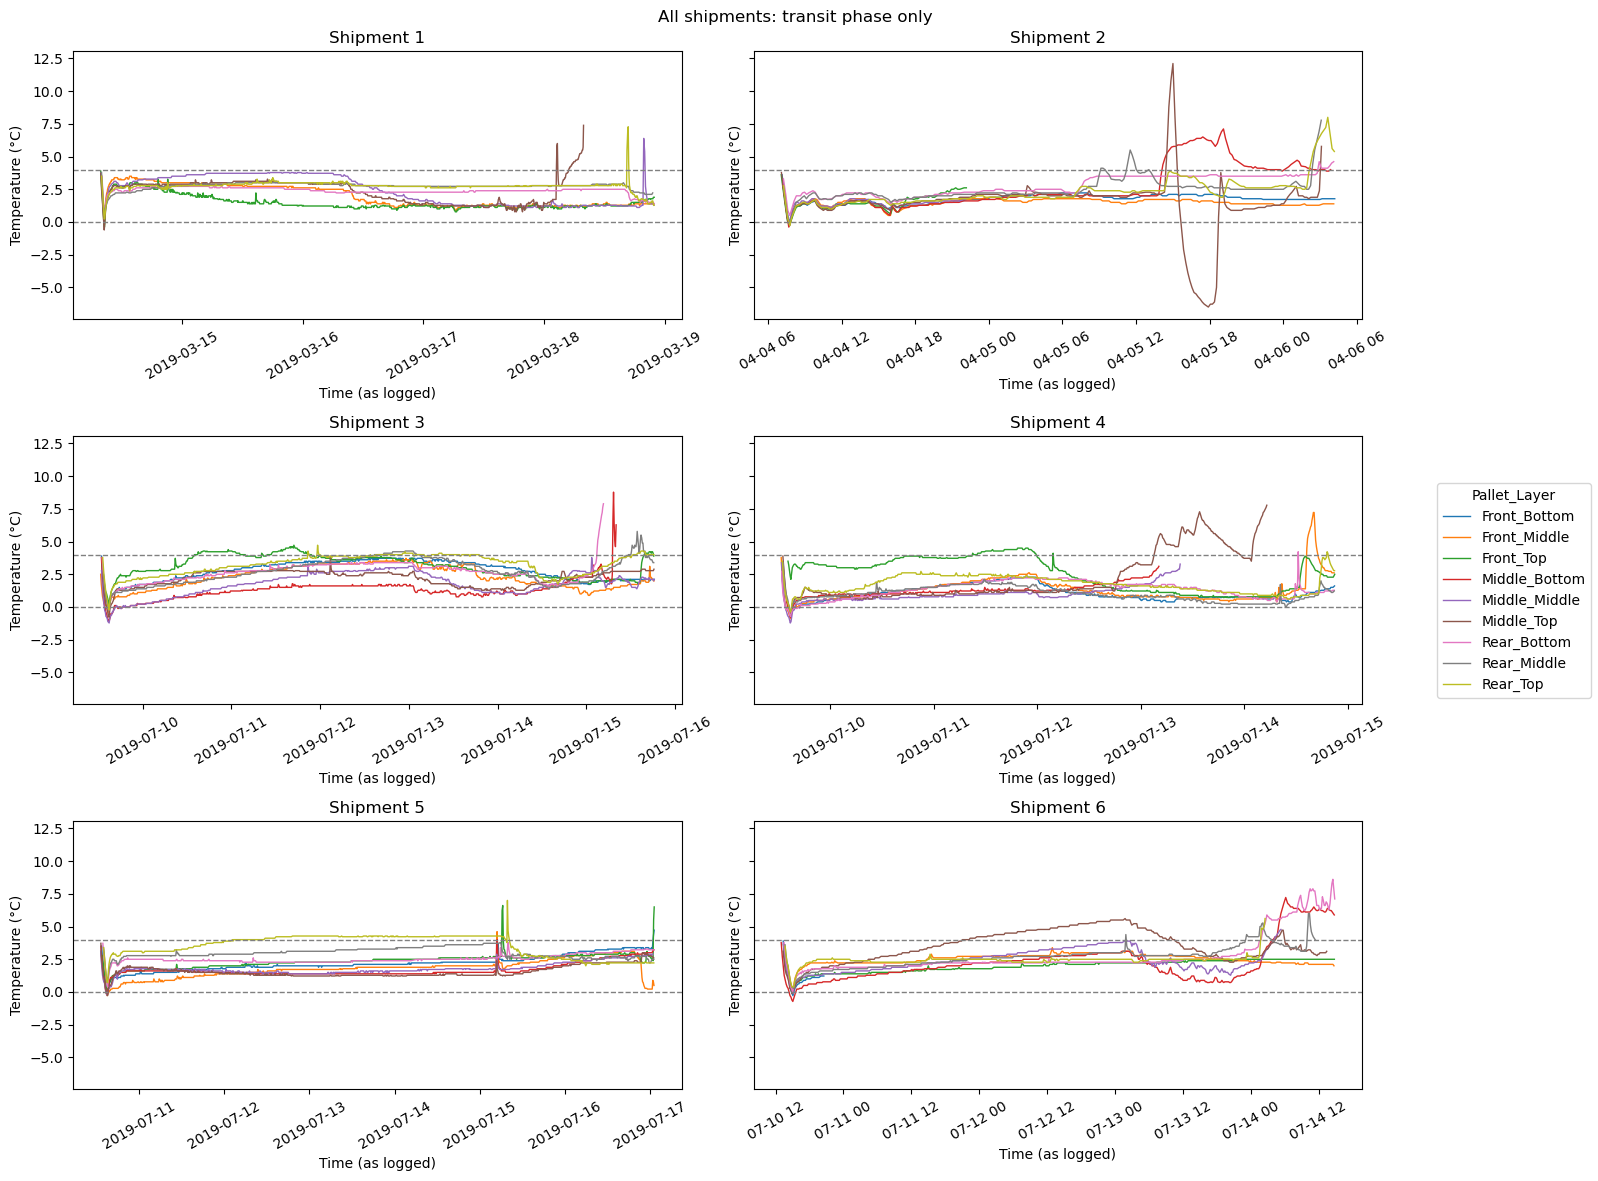


Saved ../data/processed/strawberry_clean.csv
Rows: saved 35808, reloaded 35808
                         saved        reloaded
shipment                 int64           int64
pallet                  object          object
layer                   object          object
time            datetime64[ns]  datetime64[ns]
temp_f                 float64         float64
temp_c                 float64         float64
phase                   object          object
partial_sensor            bool            bool
handling_event            bool            bool
Reload check passed


In [33]:
# Step 7: apply the trimming rules, label phases, and save the clean table

# Sensors that only cover ~10-19 hours of their window: keep, but mark
PARTIAL_SENSORS = {(6, "Front", "Bottom"), (2, "Front", "Top"), (2, "Middle", "Middle")}

clean_parts = []
sensor_summary = []

for (shipment, pallet, layer), sensor_df in df_trip.groupby(["shipment", "pallet", "layer"]):
    cooled_at, left_cold_at = find_left_cold(sensor_df)  # helper from Step 6b
    assert cooled_at is not None, f"S{shipment}_{pallet}_{layer} never cooled to {COLD_C}°C"

    # Drop everything from the moment the pallet left the cold
    if left_cold_at is not None:
        sensor_df = sensor_df[sensor_df["time"] < left_cold_at]

    sensor_df = sensor_df.copy()  # a separate copy, so adding columns can't touch df_trip
    sensor_df["phase"] = "transit"
    sensor_df.loc[sensor_df["time"] < cooled_at, "phase"] = "precool"
    sensor_df["partial_sensor"] = (shipment, pallet, layer) in PARTIAL_SENSORS
    clean_parts.append(sensor_df)

    transit_times = sensor_df.loc[sensor_df["phase"] == "transit", "time"]
    sensor_summary.append({
        "shipment": shipment,
        "pallet_layer": f"{pallet}_{layer}",
        "precool_hours": (cooled_at - sensor_df["time"].min()) / pd.Timedelta(hours=1),
        "transit_hours": (transit_times.max() - transit_times.min()) / pd.Timedelta(hours=1),
        "left_cold_at": left_cold_at if left_cold_at is not None else "stayed cold",
        "partial_sensor": (shipment, pallet, layer) in PARTIAL_SENSORS,
    })

df_clean = pd.concat(clean_parts, ignore_index=True)

# The S2_Middle_Top warm spike + -6.5°C dip: keep, but mark
df_clean["handling_event"] = (
    (df_clean["shipment"] == 2)
    & (df_clean["pallet"] == "Middle")
    & (df_clean["layer"] == "Top")
    & df_clean["time"].between("2019-04-05 14:00", "2019-04-05 20:00")
)

sensor_summary = pd.DataFrame(sensor_summary)
print(sensor_summary.round(1).to_string(index=False))

is_transit = df_clean["phase"] == "transit"
is_usable = is_transit & ~df_clean["partial_sensor"] & ~df_clean["handling_event"]
print(f"\nRows in df_clean: {len(df_clean)}")
print(f"Transit rows: {is_transit.sum()}")
print(f"Transit rows excluding partial sensors and the handling event: {is_usable.sum()}")

# Transit hours per shipment (summed over full sensors), and the trip's longest single-sensor transit
full = sensor_summary[~sensor_summary["partial_sensor"]]
print("\nTransit hours per shipment (full sensors only):")
print(full.groupby("shipment")["transit_hours"].agg(sensors="count", sensor_hours="sum", longest="max").round(1).to_string())

# All six shipments, transit rows only (same grid as Step 6a)
transit_df = df_clean[is_transit]
fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharey=True)
lines_for_legend = {}

for ax, (shipment, ship_df) in zip(axes.flat, transit_df.groupby("shipment")):
    for (pallet, layer), sensor_df in ship_df.groupby(["pallet", "layer"]):
        sensor_df = sensor_df.sort_values("time")
        position = f"{pallet}_{layer}"
        (line,) = ax.plot(sensor_df["time"], sensor_df["temp_c"], color=position_colors[position], linewidth=1)
        lines_for_legend[position] = line

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.axhline(4, color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"Shipment {shipment}")
    ax.set_xlabel("Time (as logged)")
    ax.set_ylabel("Temperature (°C)")
    ax.tick_params(axis="x", labelrotation=30)

fig.legend(
    [lines_for_legend[p] for p in positions], positions,
    title="Pallet_Layer", loc="center right",
)
fig.suptitle("All shipments: transit phase only")
plt.tight_layout(rect=(0, 0, 0.88, 1))
plt.show()

# Save, then reload to check nothing changed on the way to disk
processed_dir = data_dir.parent / "processed"  # model/data/processed (gitignored)
processed_dir.mkdir(parents=True, exist_ok=True)
clean_path = processed_dir / "strawberry_clean.csv"
df_clean.to_csv(clean_path, index=False)

reloaded = pd.read_csv(clean_path, parse_dates=["time"])
print(f"\nSaved {clean_path}")
print(f"Rows: saved {len(df_clean)}, reloaded {len(reloaded)}")
print(pd.DataFrame({"saved": df_clean.dtypes, "reloaded": reloaded.dtypes}).to_string())
assert len(reloaded) == len(df_clean)
assert (reloaded.dtypes == df_clean.dtypes).all()
pd.testing.assert_frame_equal(reloaded, df_clean)  # values too, not just shape
print("Reload check passed")

## Step 8a: is any trailer position consistently warmer?

**What:** For each shipment, takes every sensor's average transit temperature and subtracts its own truck's average. The difference is the sensor's *offset*: how much warmer or colder it runs than its truck. It then counts in how many shipments each position, pallet and layer ran warmer than its truck.

**Why:**
- All sensors in one truck share the same outside conditions, so the real sample size is **6 trucks**, not thousands of readings.
- Comparing each sensor with its own truck removes truck-to-truck differences.
- Counting shipments tests whether a pattern is **consistent**, rather than driven by one unusual truck.
- Averaging per sensor first stops sensors that log more often from counting more.
- This cell reads the saved CSV, so it runs without the earlier cells.

**Result:**
- The **Rear pallet runs warmer in 5 of 6 shipments**, by about **+0.3°C**. `Front_Middle` is colder in 6 of 6 (−0.32°C).
- Layer (Top/Middle/Bottom) barely matters.
- **For scale:** usable transit readings have a standard deviation (typical spread) of **1.03°C**, and 90% fall between 0.7 and 4.0°C. Position effects are real but small.

In [ ]:
# Step 8a: is any trailer position consistently warmer or colder than its own truck?
from pathlib import Path
import pandas as pd

clean = pd.read_csv(Path("../data/processed/strawberry_clean.csv"), parse_dates=["time"])
usable = clean[(clean["phase"] == "transit") & ~clean["partial_sensor"] & ~clean["handling_event"]].copy()
usable["pallet_layer"] = usable["pallet"] + "_" + usable["layer"]

# One mean per sensor, so a sensor that logs twice as often doesn't count twice
sensor_means = usable.groupby(["shipment", "pallet", "layer", "pallet_layer"])["temp_c"].mean().reset_index()

# Offset = sensor mean minus its own truck's average over sensors (removes truck-to-truck differences)
sensor_means["offset"] = sensor_means["temp_c"] - sensor_means.groupby("shipment")["temp_c"].transform("mean")


def offset_table(group_column):
    """Offsets per shipment for one grouping, plus the mean and a 'warmer in N of M' count."""
    table = sensor_means.groupby([group_column, "shipment"])["offset"].mean().unstack("shipment")
    shipment_columns = list(table.columns)
    warmer = (table[shipment_columns] > 0).sum(axis=1)
    present = table[shipment_columns].notna().sum(axis=1)  # S1 has no Front_Bottom / Middle_Bottom
    table["mean_offset"] = table[shipment_columns].mean(axis=1)
    table["warmer_in"] = warmer.astype(str) + " of " + present.astype(str)
    return table.sort_values("mean_offset", ascending=False).round(2)


print("Offset from own truck's average (°C), by position:")
print(offset_table("pallet_layer").to_string())
print("\nBy pallet only:")
print(offset_table("pallet").to_string())
print("\nBy layer only:")
print(offset_table("layer").to_string())

# For scale: how spread out are usable transit temperatures?
low, high = usable["temp_c"].quantile([0.05, 0.95])
print(f"\nAll usable transit readings: std {usable['temp_c'].std():.2f} °C, 5th-95th percentile {low:.1f} to {high:.1f} °C")
print(f"Sensor offsets: std {sensor_means['offset'].std():.2f} °C")

## Step 8b: does temperature drift during a trip?

**What:** For each shipment, fits a straight line of temperature against hours in transit and reports its slope in °C per day.

**Why:** If cargo slowly warms over a long trip, a longer route costs more than its hours alone suggest. A straight line is the simplest way to measure such a trend.

**Result:**

| Shipment | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| Slope (°C/day) | −0.27 | +1.00 | +0.11 | +0.07 | +0.14 | +0.48 |

- The three cleanest trips (3, 4 and 5) drift about **+0.1°C per day**.
- The larger slopes in Shipments 2 and 6 come from **a few sensors warming late** in the trip, not from the whole truck warming.

In [ ]:
# Step 8b: does cargo temperature drift with time in transit?
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

clean = pd.read_csv(Path("../data/processed/strawberry_clean.csv"), parse_dates=["time"])
usable = clean[(clean["phase"] == "transit") & ~clean["partial_sensor"] & ~clean["handling_event"]].copy()

# Hours since each sensor's own first transit reading
sensor_columns = ["shipment", "pallet", "layer"]
first_transit = usable.groupby(sensor_columns)["time"].transform("min")
usable["hours_in_transit"] = (usable["time"] - first_transit) / pd.Timedelta(hours=1)

fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharey=True)
fits = []

for ax, (shipment, ship_df) in zip(axes.flat, usable.groupby("shipment")):
    # Straight line temp_c = slope * hours + intercept through all of this shipment's usable rows
    slope, intercept = np.polyfit(ship_df["hours_in_transit"], ship_df["temp_c"], 1)
    fits.append({
        "shipment": shipment,
        "slope_c_per_day": slope * 24,
        "start_temp_c": intercept,  # the fitted line's value at hour 0
        "usable_sensors": ship_df.groupby(["pallet", "layer"]).ngroups,
    })

    for _, sensor_df in ship_df.groupby(["pallet", "layer"]):
        sensor_df = sensor_df.sort_values("time")
        ax.plot(sensor_df["hours_in_transit"], sensor_df["temp_c"], color="gray", linewidth=0.6, alpha=0.6)

    x = np.array([0, ship_df["hours_in_transit"].max()])
    ax.plot(x, slope * x + intercept, color="red", linewidth=2, label=f"fit: {slope * 24:+.2f} °C/day")
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.axhline(4, color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"Shipment {shipment}")
    ax.set_xlabel("Hours in transit (h)")
    ax.set_ylabel("Temperature (°C)")
    ax.legend(loc="upper left")

fig.suptitle("Transit temperature vs time in transit (gray = sensors, red = straight-line fit)")
plt.tight_layout()
plt.show()

print(pd.DataFrame(fits).round(2).to_string(index=False))

## Key findings

- **52 raw sensor files** from 6 shipments came in 4 different layouts. All of them load with no bad values: 68,332 readings.
- The sensors recorded well before and after the trips. After trimming to the paper's trip windows and cutting each pallet when it left the cold, **32,047 usable transit readings** remain, saved to `model/data/processed/strawberry_clean.csv`.
- During transit, refrigeration kept the cargo **mostly between 0.7 and 4.0°C**.
- The **rear pallet runs about 0.3°C warmer** than its truck's average (5 of 6 shipments), and temperature **drifts up about 0.1°C per day** in the cleanest trips. Both effects are small.
- The biggest temperature swings come from **events**: door-opening spikes, warm spots, and pallets being unloaded.

## Limitations

- **Only 6 trucks.** All sensors in a truck share the same trip, so this is about 29 days of trips, not thousands of independent samples.
- **No GPS or route data.** Readings can't yet be matched to outside weather.
- **The time zone of the logged times is unknown.**
- **Trip windows** start up to 16 minutes off from the authors' own trimming.
- **Judgment calls:** the "left the cold" thresholds (4°C, 8°C, 2 hours) were chosen for this project.
- **Flagged, not removed:** S2_Middle_Top's −6.5°C event and three partial sensors. Later steps decide whether to use them.